# 👥 Exploratory Data Analysis (EDA): Tingkat Kemiskinan (P0) Provinsi di Indonesia (2018–2025)

**Mata Kuliah:** Presentasi dan Storytelling Data  
**Topik:** Analisis Disparitas Spasial, Kesenjangan Desa-Kota, dan Dinamika Kemiskinan Multitahun  
**Dataset:** `dataset_penduduk/kemiskinan_p0_provinsi_2018_2025.csv` (Badan Pusat Statistik - BPS)  

---

## 📌 1. Latar Belakang & Konteks Analisis
**Persentase Penduduk Miskin ($P_0$ / Headcount Index)** adalah salah satu indikator makroekonomi dan kesejahteraan paling fundamental yang dirilis oleh Badan Pusat Statistik (BPS) dua kali setahun (Maret dan September). 

Indikator ini mengukur proporsi penduduk yang memiliki rata-rata pengeluaran konsumsi per kapita per bulan di bawah **Garis Kemiskinan (GK)**, yang mencakup:
- **Garis Kemiskinan Makanan (GKM):** Nilai rupiah pengeluaran kebutuhan minimum makanan (disetarakan dengan 2.100 kkal per kapita per hari). GKM berkontribusi sekitar **74–75%** terhadap total Garis Kemiskinan!
- **Garis Kemiskinan Non-Makanan (GKNM):** Kebutuhan minimum perumahan, sandang, pendidikan, dan kesehatan.

Karena komponen makanan menyumbang porsi terbesar garis kemiskinan, isu kemiskinan berkorelasi sangat erat dengan ketahanan pangan, daya beli, dan volatilitas harga bahan pokok.

Notebook ini mengeksplorasi tren kemiskinan 38 provinsi di Indonesia selama periode **2018 hingga 2025**, menelaah dampak krisis COVID-19, jurang pemisah perkotaan-perdesaan (*urban-rural divide*), disparitas antar-pulau, serta laju pemulihan kemiskinan daerah.


In [1]:
# Setup library analisis data & visualisasi
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi estetika visualisasi
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.autolayout'] = True
sns.set_palette('tab10')

print("✅ Library analisis berhasil dimuat!")


✅ Library analisis berhasil dimuat!


## 🧹 2. Pemuatan Data & Pemeriksaan Kualitas (Data Ingestion & Integrity)

Mari kita baca berkas `kemiskinan_p0_provinsi_2018_2025.csv` dan periksa kebersihan data. Terdapat beberapa karakteristik data resmi BPS yang perlu dicermati:
1. **Semester 2 (September) 2023:** Seluruh data provinsi bernilai `NaN` karena BPS meniadakan rilis kemiskinan September 2023 sehubungan dengan pelaksanaan Sensus Pertanian 2023 (ST2023).
2. **DKI Jakarta:** Kolom `perdesaan_persen` bernilai `NaN` karena DKI Jakarta berstatus 100% wilayah perkotaan (*urbanized area*).
3. **Provinsi Pemekaran Baru Papua (DOB):** Papua Barat Daya, Papua Pegunungan, Papua Selatan, dan Papua Tengah baru memiliki data per 2024 setelah pembentukan kelembagaan provinsi tuntas.
4. **Entitas 'INDONESIA':** Merupakan nilai rata-rata nasional yang perlu dipisahkan saat menganalisis perbandingan antar-provinsi.


In [2]:
# Membaca dataset kemiskinan BPS
raw_data_dir = os.path.join('..', 'data', 'raw') if os.path.exists(os.path.join('..', 'data', 'raw')) else (os.path.join('data', 'raw') if os.path.exists(os.path.join('data', 'raw')) else '.')
csv_path = os.path.join(raw_data_dir, 'dataset_penduduk', 'kemiskinan_p0_provinsi_2018_2025.csv')
df_raw = pd.read_csv(csv_path)

# Standardisasi teks
df_kemiskinan = df_raw.copy()
df_kemiskinan['provinsi'] = df_kemiskinan['provinsi'].str.strip()

# Menambahkan kolom label periode ringkas (e.g. '2018-M' untuk Maret, '2018-S' untuk September)
def get_label_periode(row):
    sem = 'M' if 'Maret' in row['periode'] else 'S'
    return f"{row['tahun']}-{sem}"

df_kemiskinan['label_periode'] = df_kemiskinan.apply(get_label_periode, axis=1)

# Menghitung jurang kemiskinan desa - kota (Urban-Rural Poverty Gap)
df_kemiskinan['gap_desa_kota'] = df_kemiskinan['perdesaan_persen'] - df_kemiskinan['perkotaan_persen']

# Pemetaan wilayah pulau besar
def map_pulau(prov):
    prov = prov.upper()
    if any(p in prov for p in ['ACEH', 'SUMATERA', 'RIAU', 'JAMBI', 'BENGKULU', 'LAMPUNG', 'BANGKA', 'BELITUNG']):
        return 'Sumatera'
    elif any(p in prov for p in ['JAKARTA', 'JAWA', 'YOGYAKARTA', 'BANTEN']):
        return 'Jawa'
    elif any(p in prov for p in ['BALI', 'NUSA TENGGARA']):
        return 'Bali & Nusa Tenggara'
    elif 'KALIMANTAN' in prov:
        return 'Kalimantan'
    elif any(p in prov for p in ['SULAWESI', 'GORONTALO']):
        return 'Sulawesi'
    elif 'MALUKU' in prov:
        return 'Maluku'
    elif 'PAPUA' in prov:
        return 'Papua'
    return 'Nasional'

df_kemiskinan['wilayah_pulau'] = df_kemiskinan['provinsi'].apply(map_pulau)

# Pisahkan benchmark nasional dengan data provinsi
df_nasional = df_kemiskinan[df_kemiskinan['provinsi'] == 'INDONESIA'].copy()
df_prov = df_kemiskinan[df_kemiskinan['provinsi'] != 'INDONESIA'].copy()

print(f"Total baris data : {len(df_kemiskinan)} baris")
print(f"Data Provinsi    : {len(df_prov)} baris ({df_prov['provinsi'].nunique()} provinsi unik)")
print(f"Data Nasional    : {len(df_nasional)} baris")
print(f"Rentang Tahun    : {sorted(df_kemiskinan['tahun'].unique())}")


Total baris data : 624 baris
Data Provinsi    : 608 baris (38 provinsi unik)
Data Nasional    : 16 baris
Rentang Tahun    : [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## 📊 3. Struktur Data & Statistik Ringkasan

Mari kita amati profil ringkasan statistik dari persentase kemiskinan total, perkotaan, dan perdesaan.


In [3]:
print("=== RINGKASAN DATA KEMISKINAN PROVINSI ===")
display(df_prov[['total_persen', 'perkotaan_persen', 'perdesaan_persen', 'gap_desa_kota']].describe().round(2))

print("\n=== CONTOH 5 BARIS TERAKHIR (TAHUN 2025) ===")
display(df_prov.dropna(subset=['total_persen']).tail(5))


=== RINGKASAN DATA KEMISKINAN PROVINSI ===


,total_persen,perkotaan_persen,perdesaan_persen,gap_desa_kota
count,526.00,526.00,511.00,511.00
mean,10.53,7.01,13.37,6.27
std,5.71,2.97,8.02,8.15
min,3.42,2.78,4.25,-5.10
25%,6.27,4.69,7.64,1.40
50%,8.85,6.12,11.26,3.51
75%,13.01,9.05,14.63,6.56
max,32.97,16.56,39.14,33.66



=== CONTOH 5 BARIS TERAKHIR (TAHUN 2025) ===


,provinsi,tahun,periode,perkotaan_persen,perdesaan_persen,total_persen,label_periode,gap_desa_kota,wilayah_pulau
617,PAPUA SELATAN,2025,Semester 2 (September),4.93,27.79,19.26,2025-S,22.86,Papua
618,PAPUA TENGAH,2025,Semester 1 (Maret),5.51,36.54,28.90,2025-M,31.03,Papua
619,PAPUA TENGAH,2025,Semester 2 (September),6.54,39.14,29.45,2025-S,32.60,Papua
620,PAPUA PEGUNUNGAN,2025,Semester 1 (Maret),13.00,31.36,30.03,2025-M,18.36,Papua
621,PAPUA PEGUNUNGAN,2025,Semester 2 (September),13.06,30.25,27.21,2025-S,17.19,Papua


## 📈 4. Tren Kemiskinan Nasional (2018–2025): Guncangan Pandemi & Pemulihan

Bagaimana lintasan kemiskinan nasional selama 8 tahun terakhir? Kita dapat melihat tiga babak penting:
1. **Fase Pra-Pandemi (2018–2019):** Kemiskinan turun ke rekor terendah di bawah 9,4%.
2. **Fase Shock COVID-19 (2020–2021):** Terjadi pembalikan tren (*reversal*), kemiskinan melonjak menembus 10,19% pada September 2020.
3. **Fase Pemulihan & Laju Penurunan (2022–2025):** Kemiskinan kembali melandai turun ke 8,25%–8,57% pada 2025.


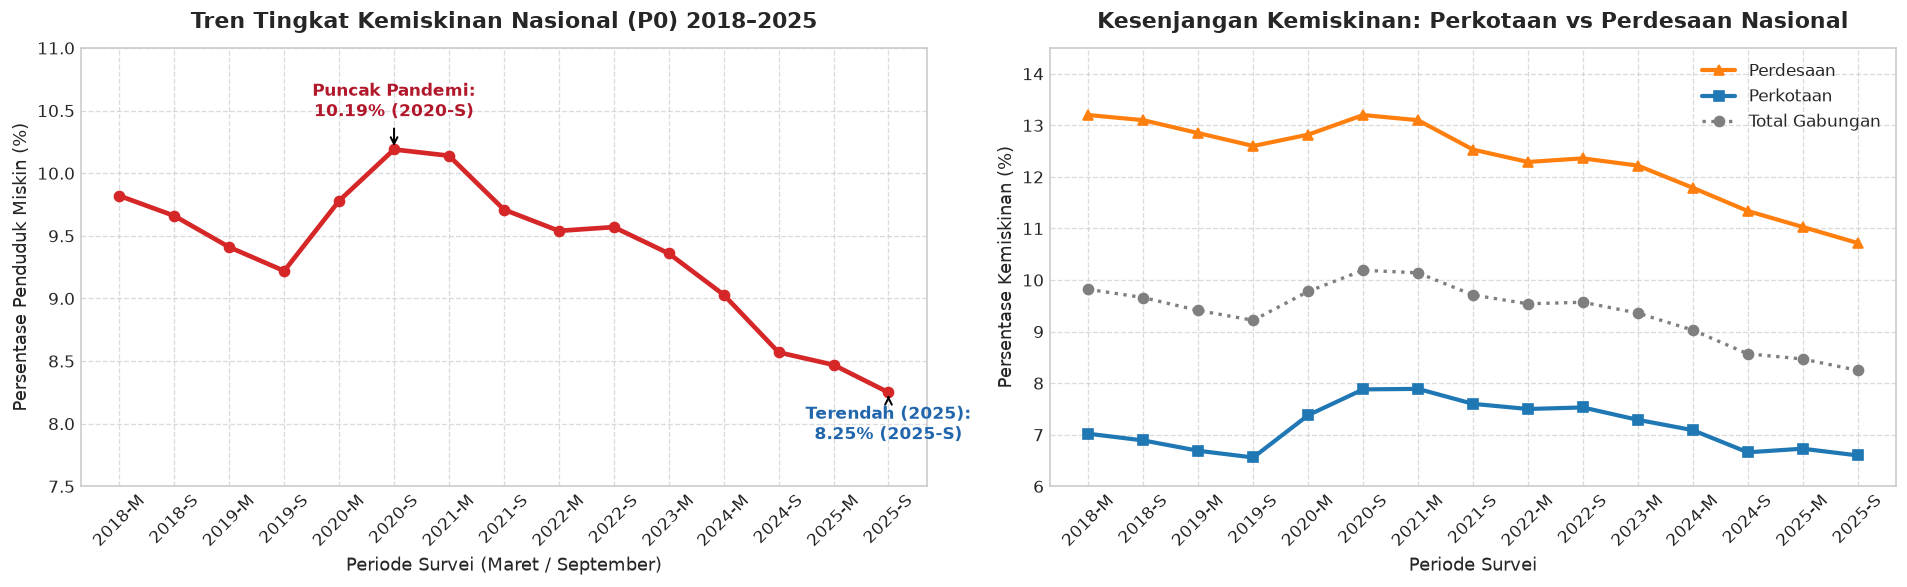

Data Nasional per Periode:


,tahun,periode,perkotaan_persen,perdesaan_persen,total_persen
76,2018,Semester 1 (Maret),7.02,13.20,9.82
77,2018,Semester 2 (September),6.89,13.10,9.66
154,2019,Semester 1 (Maret),6.69,12.85,9.41
155,2019,Semester 2 (September),6.56,12.60,9.22
232,2020,Semester 1 (Maret),7.38,12.82,9.78
233,2020,Semester 2 (September),7.88,13.20,10.19
310,2021,Semester 1 (Maret),7.89,13.10,10.14
311,2021,Semester 2 (September),7.60,12.53,9.71
388,2022,Semester 1 (Maret),7.50,12.29,9.54
389,2022,Semester 2 (September),7.53,12.36,9.57


In [4]:
# Visualisasi Tren Kemiskinan Nasional
df_nas_clean = df_nasional.dropna(subset=['total_persen']).copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Garis Tren Kemiskinan Total Nasional
axes[0].plot(df_nas_clean['label_periode'], df_nas_clean['total_persen'], marker='o', linewidth=2.8, color='#d62728', label='Total Kemiskinan Nasional')
axes[0].set_title('Tren Tingkat Kemiskinan Nasional (P0) 2018–2025', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Periode Survei (Maret / September)', fontsize=11)
axes[0].set_ylabel('Persentase Penduduk Miskin (%)', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylim(7.5, 11.0)
axes[0].grid(True, linestyle='--', alpha=0.7)

# Anotasi titik ekstrem
min_row = df_nas_clean.loc[df_nas_clean['total_persen'].idxmin()]
max_row = df_nas_clean.loc[df_nas_clean['total_persen'].idxmax()]
axes[0].annotate(f"Puncak Pandemi:\n{max_row['total_persen']:.2f}% ({max_row['label_periode']})", 
                 (max_row['label_periode'], max_row['total_persen']),
                 xytext=(0, 20), textcoords='offset points', ha='center',
                 arrowprops=dict(arrowstyle='->', color='black', lw=1.2), fontweight='bold', color='#b2182b')

axes[0].annotate(f"Terendah (2025):\n{min_row['total_persen']:.2f}% ({min_row['label_periode']})", 
                 (min_row['label_periode'], min_row['total_persen']),
                 xytext=(0, -28), textcoords='offset points', ha='center',
                 arrowprops=dict(arrowstyle='->', color='black', lw=1.2), fontweight='bold', color='#2166ac')

# Plot 2: Perbandingan Perkotaan vs Perdesaan Nasional
axes[1].plot(df_nas_clean['label_periode'], df_nas_clean['perdesaan_persen'], marker='^', linewidth=2.5, color='#ff7f0e', label='Perdesaan')
axes[1].plot(df_nas_clean['label_periode'], df_nas_clean['perkotaan_persen'], marker='s', linewidth=2.5, color='#1f77b4', label='Perkotaan')
axes[1].plot(df_nas_clean['label_periode'], df_nas_clean['total_persen'], marker='o', linewidth=2, color='#7f7f7f', linestyle=':', label='Total Gabungan')
axes[1].set_title('Kesenjangan Kemiskinan: Perkotaan vs Perdesaan Nasional', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Periode Survei', fontsize=11)
axes[1].set_ylabel('Persentase Kemiskinan (%)', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(6.0, 14.5)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

print("Data Nasional per Periode:")
display(df_nas_clean[['tahun', 'periode', 'perkotaan_persen', 'perdesaan_persen', 'total_persen']])


## 🌾 vs 🏙️ 5. Analisis Kesenjangan Struktural: Urban vs Rural Poverty Gap

Dari grafik nasional di atas, terlihat fenomena fundamental: **kemiskinan di perdesaan secara konsisten berlipat ganda lebih tinggi dibanding perkotaan** (~11%–13% berbanding ~7%–8%).

Mari kita investigasi di tingkat provinsi: provinsi mana yang memiliki jurang kemiskinan desa-kota (*gap*) paling curam?


findfont: Failed to find font weight semibold, now using 700.


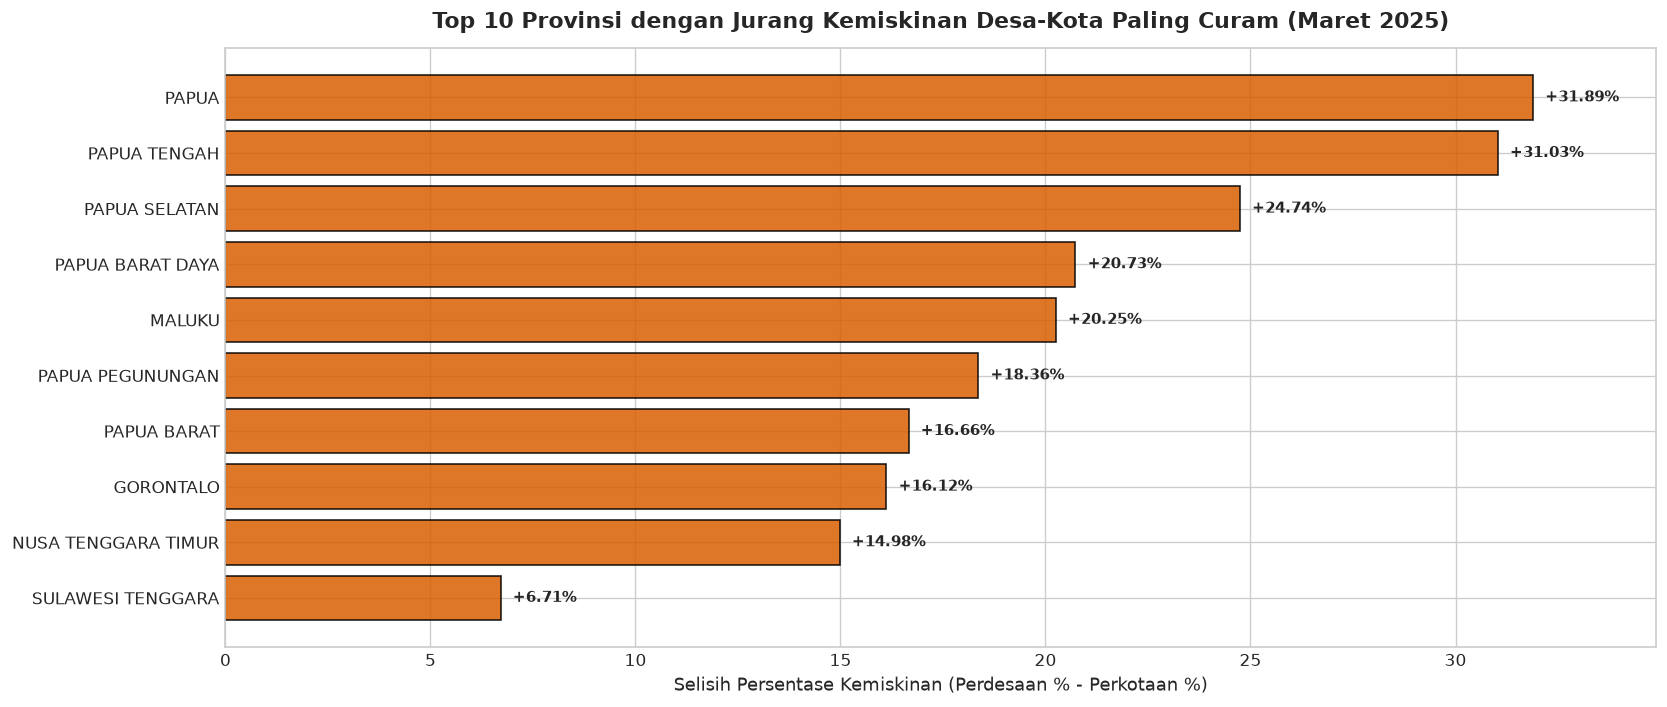

Rincian Top 5 Provinsi dengan Ketimpangan Desa-Kota Tertinggi:


,provinsi,perdesaan_persen,perkotaan_persen,gap_desa_kota,total_persen
614,PAPUA,38.47,6.58,31.89,19.16
618,PAPUA TENGAH,36.54,5.51,31.03,28.90
616,PAPUA SELATAN,28.86,4.12,24.74,19.71
612,PAPUA BARAT DAYA,29.71,8.98,20.73,17.95
606,MALUKU,24.61,4.36,20.25,15.38
620,PAPUA PEGUNUNGAN,31.36,13.00,18.36,30.03
610,PAPUA BARAT,25.88,9.22,16.66,20.66
602,GORONTALO,20.80,4.68,16.12,13.24
582,NUSA TENGGARA TIMUR,22.66,7.68,14.98,18.60
600,SULAWESI TENGGARA,13.13,6.42,6.71,10.54


In [5]:
# Analisis Gap Desa-Kota per Provinsi pada data terbaru 2025 Semester 1
df_recent_gap = df_prov[(df_prov['tahun'] == 2025) & (df_prov['periode'].str.contains('Maret'))].dropna(subset=['gap_desa_kota'])

gap_sorted = df_recent_gap.sort_values(by='gap_desa_kota', ascending=False)
top_gap = gap_sorted.head(10)
bottom_gap = gap_sorted.tail(10)

plt.figure(figsize=(14, 6))
bars = plt.barh(top_gap['provinsi'][::-1], top_gap['gap_desa_kota'][::-1], color='#d95f02', edgecolor='black', alpha=0.85)
plt.title('Top 10 Provinsi dengan Jurang Kemiskinan Desa-Kota Paling Curam (Maret 2025)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Selisih Persentase Kemiskinan (Perdesaan % - Perkotaan %)', fontsize=11)
plt.ylabel('')
plt.xlim(0, max(top_gap['gap_desa_kota']) + 3)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height()/2, f"+{w:.2f}%", va='center', fontsize=9, fontweight='semibold')

plt.tight_layout()
plt.show()

print("Rincian Top 5 Provinsi dengan Ketimpangan Desa-Kota Tertinggi:")
display(top_gap[['provinsi', 'perdesaan_persen', 'perkotaan_persen', 'gap_desa_kota', 'total_persen']].round(2))


## 🗺️ 6. Pemeringkatan Provinsi: Wilayah Termiskin vs Terendah Kemiskinannya (2025)

Kita mengamati kondisi mutakhir (2025) untuk mengidentifikasi 10 provinsi dengan tingkat kemiskinan tertinggi dan 10 provinsi dengan tingkat kemiskinan terendah di Indonesia.


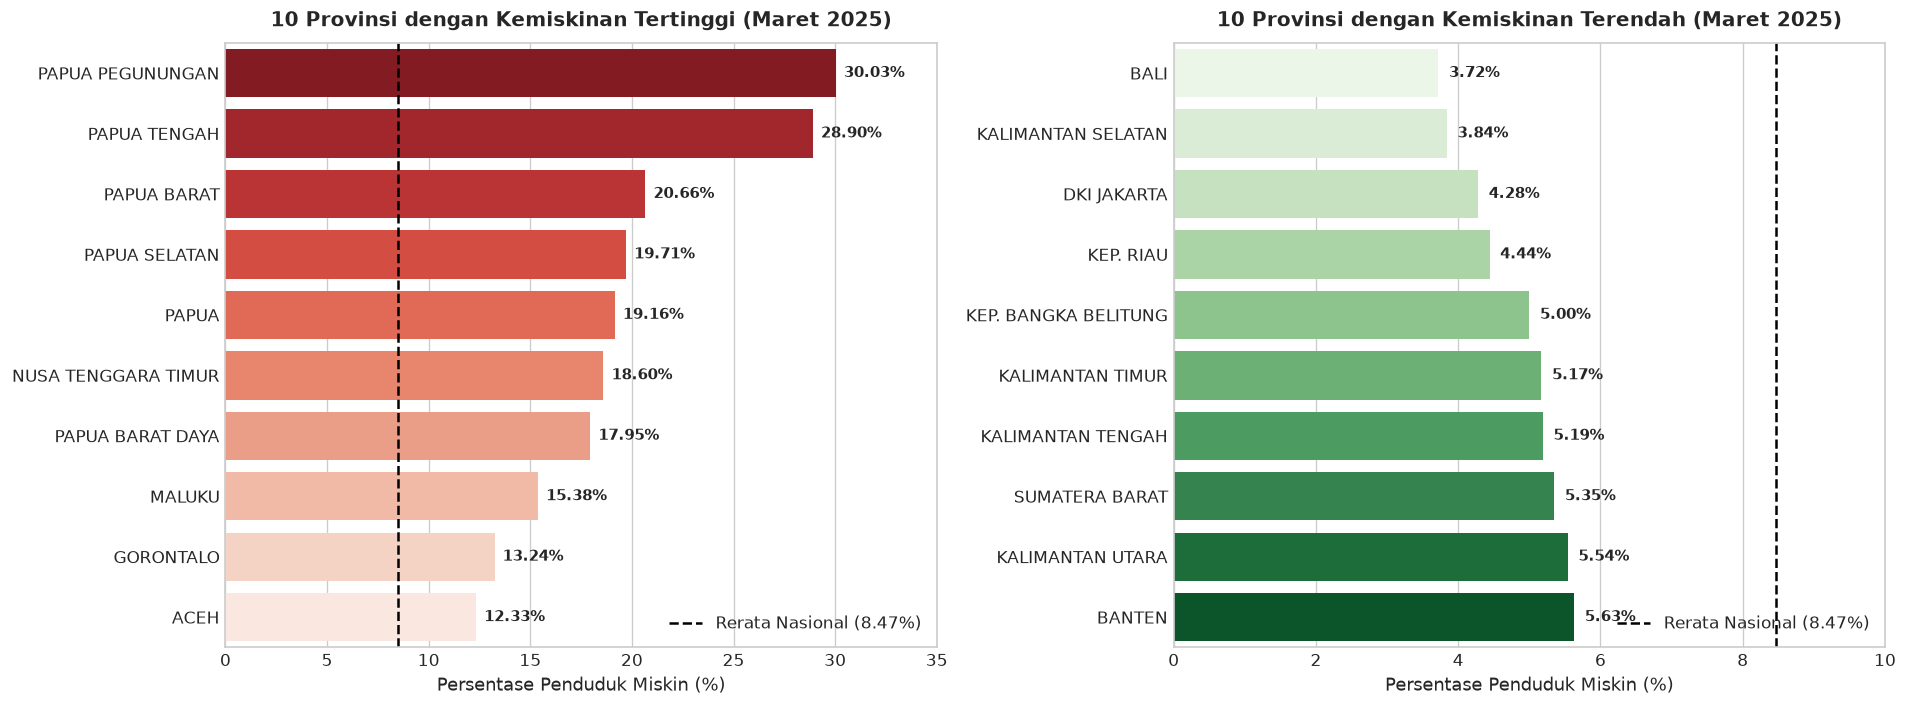

In [6]:
# Pemeringkatan 10 Tertinggi vs 10 Terendah (Maret 2025)
df_rank_2025 = df_prov[(df_prov['tahun'] == 2025) & (df_prov['periode'].str.contains('Maret'))].dropna(subset=['total_persen'])
df_rank_2025 = df_rank_2025.sort_values('total_persen', ascending=False)

top10_miskin = df_rank_2025.head(10)
bottom10_miskin = df_rank_2025.tail(10).sort_values('total_persen', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 Termiskin
sns.barplot(data=top10_miskin, y='provinsi', x='total_persen', palette='Reds_r', ax=axes[0])
axes[0].set_title('10 Provinsi dengan Kemiskinan Tertinggi (Maret 2025)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Persentase Penduduk Miskin (%)', fontsize=11)
axes[0].set_ylabel('')
axes[0].set_xlim(0, 35)
axes[0].axvline(x=df_nas_clean[df_nas_clean['label_periode'] == '2025-M']['total_persen'].values[0], 
                color='black', linestyle='--', label='Rerata Nasional (8.47%)')
axes[0].legend(loc='lower right')
for i, v in enumerate(top10_miskin['total_persen']):
    axes[0].text(v + 0.4, i, f"{v:.2f}%", va='center', fontsize=9, fontweight='semibold')

# 10 Terendah
sns.barplot(data=bottom10_miskin, y='provinsi', x='total_persen', palette='Greens', ax=axes[1])
axes[1].set_title('10 Provinsi dengan Kemiskinan Terendah (Maret 2025)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Persentase Penduduk Miskin (%)', fontsize=11)
axes[1].set_ylabel('')
axes[1].set_xlim(0, 10)
axes[1].axvline(x=df_nas_clean[df_nas_clean['label_periode'] == '2025-M']['total_persen'].values[0], 
                color='black', linestyle='--', label='Rerata Nasional (8.47%)')
axes[1].legend(loc='lower right')
for i, v in enumerate(bottom10_miskin['total_persen']):
    axes[1].text(v + 0.15, i, f"{v:.2f}%", va='center', fontsize=9, fontweight='semibold')

plt.tight_layout()
plt.show()


## 🏝️ 7. Disparitas Spasial Antar-Pulau di Indonesia

Bagaimana peta kemiskinan bila dikelompokkan ke dalam gugus kepulauan besar? Disparitas barat-timur terlihat sangat nyata di sini.


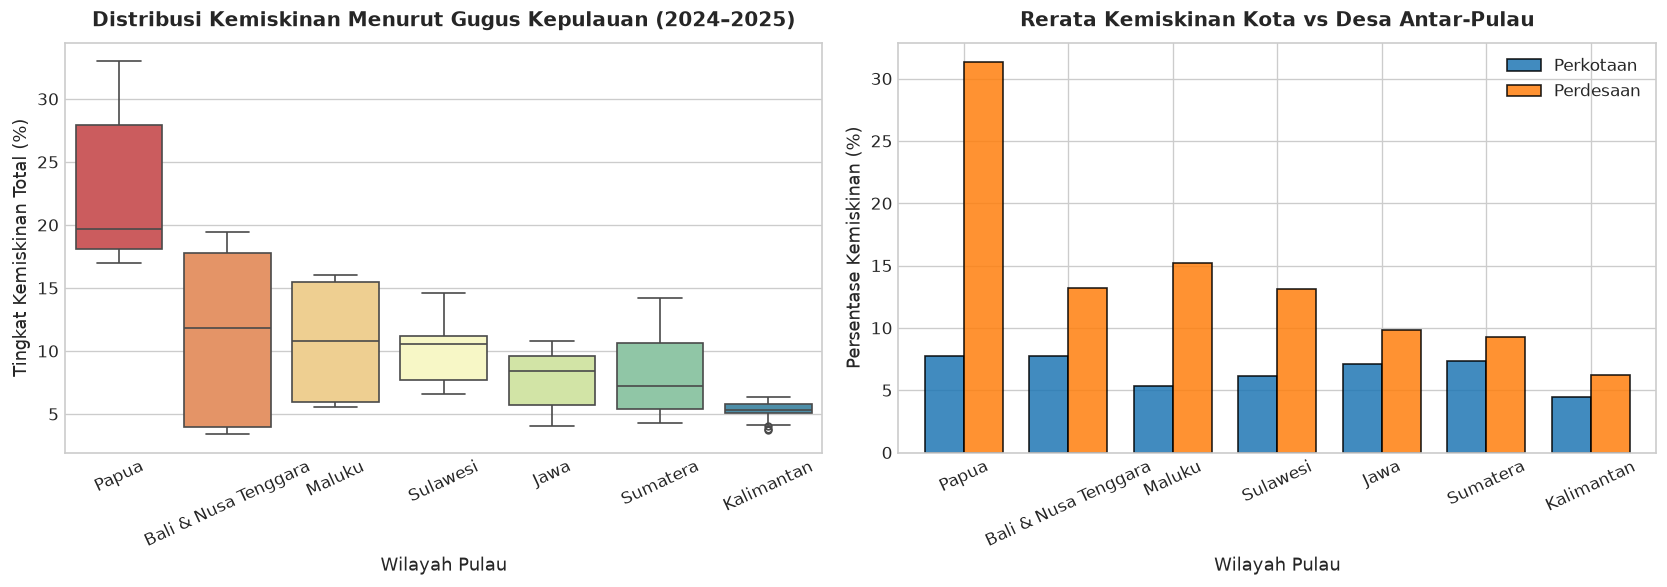

,perkotaan_persen,perdesaan_persen
wilayah_pulau,,
Papua,7.76,31.30
Bali & Nusa Tenggara,7.73,13.16
Maluku,5.37,15.22
Sulawesi,6.11,13.13
Jawa,7.13,9.81
Sumatera,7.35,9.26
Kalimantan,4.49,6.25


In [7]:
# Analisis Kemiskinan Antar-Gugus Kepulauan (Tahun 2024–2025)
df_recent_pulau = df_prov[df_prov['tahun'] >= 2024].dropna(subset=['total_persen'])

order_pulau = df_recent_pulau.groupby('wilayah_pulau')['total_persen'].median().sort_values(ascending=False).index

plt.figure(figsize=(14, 5))

# Plot 1: Boxplot per pulau
plt.subplot(1, 2, 1)
sns.boxplot(data=df_recent_pulau, x='wilayah_pulau', y='total_persen', order=order_pulau, palette='Spectral', fliersize=4)
plt.title('Distribusi Kemiskinan Menurut Gugus Kepulauan (2024–2025)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Wilayah Pulau', fontsize=11)
plt.ylabel('Tingkat Kemiskinan Total (%)', fontsize=11)
plt.xticks(rotation=25)

# Plot 2: Perbandingan Rata-rata Kemiskinan Perkotaan vs Perdesaan Antar-Pulau
plt.subplot(1, 2, 2)
urban_rural_pulau = df_recent_pulau.groupby('wilayah_pulau')[['perkotaan_persen', 'perdesaan_persen']].mean().loc[order_pulau]
urban_rural_pulau.plot(kind='bar', ax=plt.gca(), color=['#1f77b4', '#ff7f0e'], width=0.75, edgecolor='black', alpha=0.85)
plt.title('Rerata Kemiskinan Kota vs Desa Antar-Pulau', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Wilayah Pulau', fontsize=11)
plt.ylabel('Persentase Kemiskinan (%)', fontsize=11)
plt.legend(['Perkotaan', 'Perdesaan'])
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

display(urban_rural_pulau.round(2))


## 🌡️ 8. Matriks Dinamika Kemiskinan Provinsi (Heatmap 2018–2025)

Heatmap berikut memperlihatkan evolusi tingkat kemiskinan setiap provinsi dari Maret 2018 hingga Maret 2025. Zona merah tua mencerminkan kantong kemiskinan berat, sedangkan zona biru/hijau mencerminkan daerah berpendapatan relatif mapan.


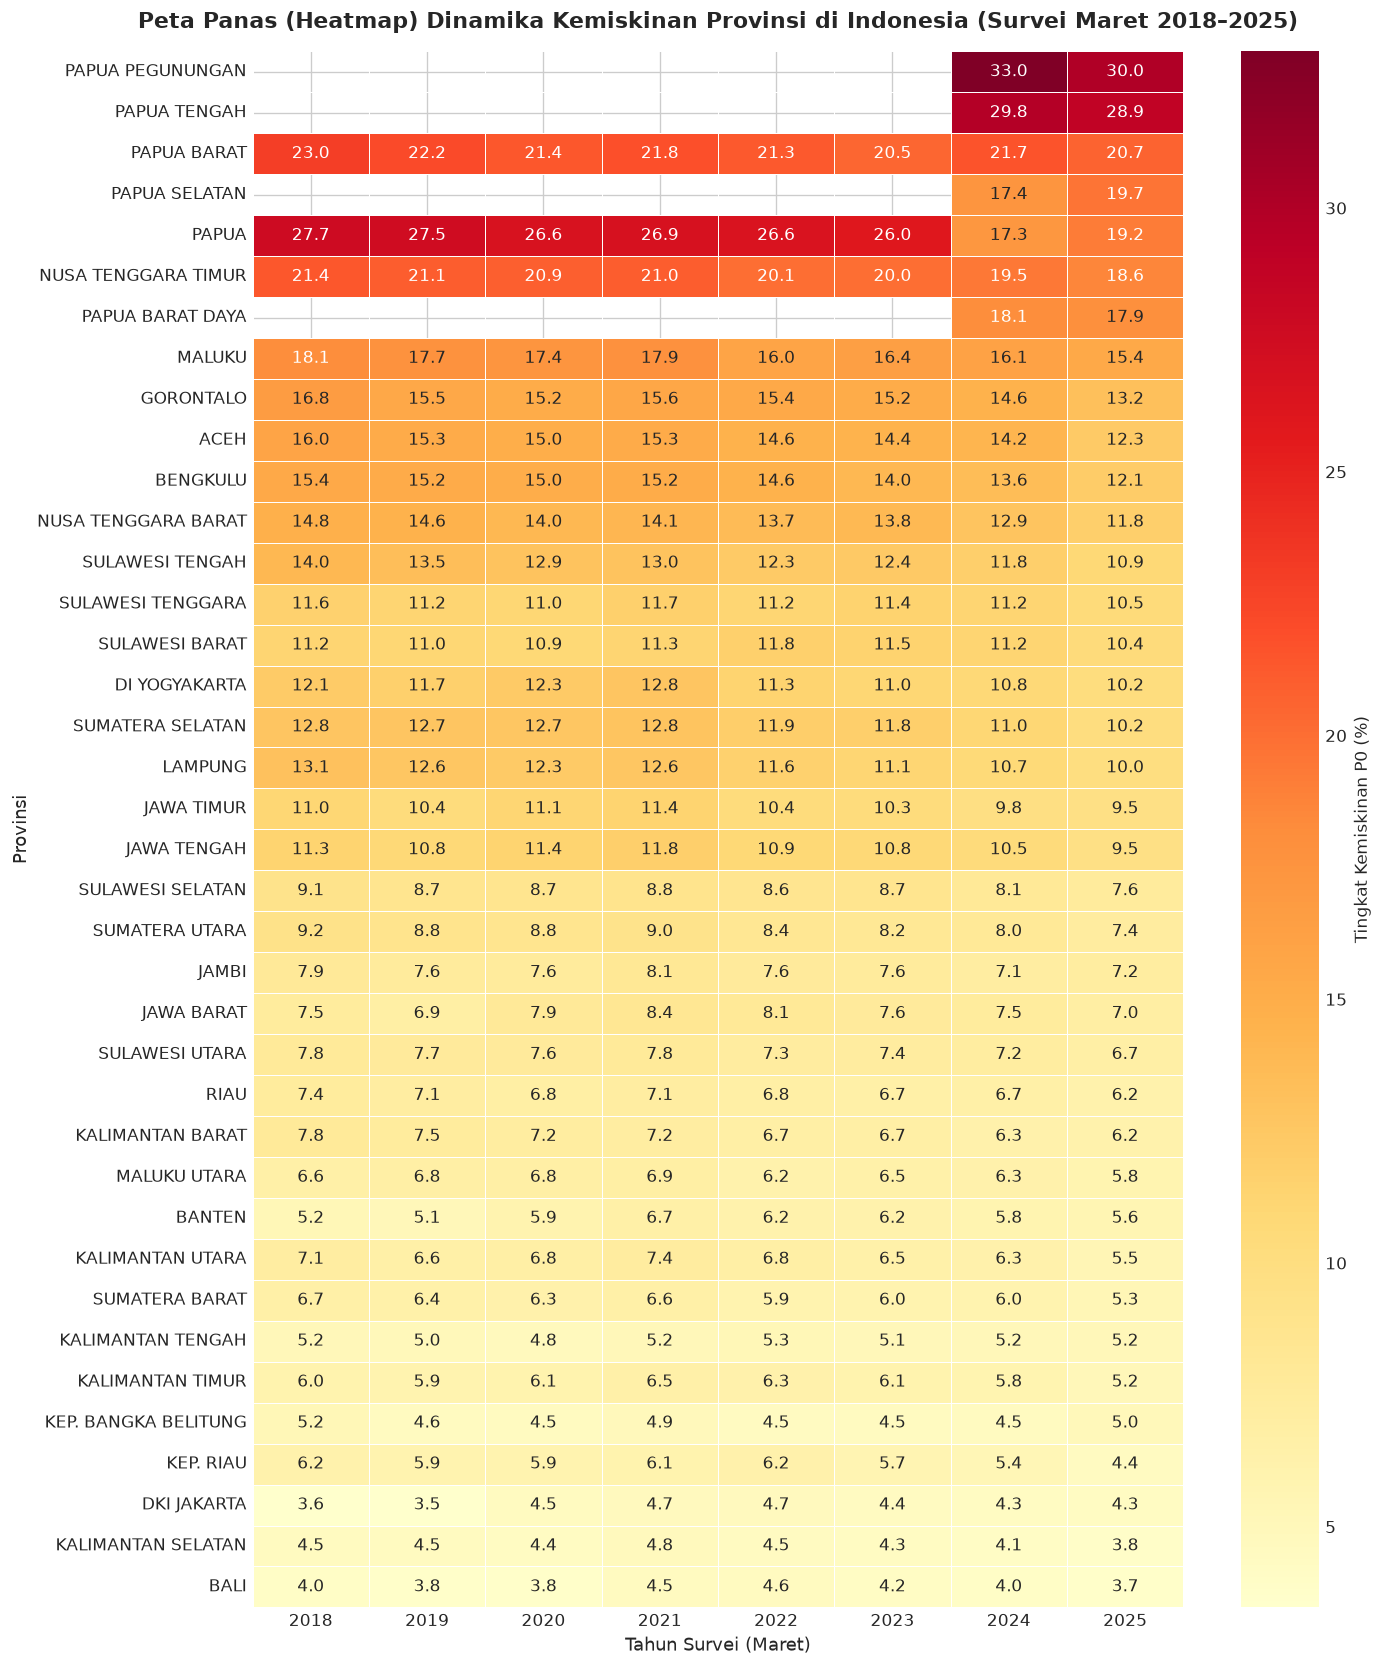

In [8]:
# Pivot table kemiskinan Maret setiap tahun untuk heatmap
df_maret = df_prov[df_prov['periode'].str.contains('Maret')].dropna(subset=['total_persen'])
pivot_kemiskinan = df_maret.pivot(index='provinsi', columns='tahun', values='total_persen')

# Urutkan provinsi berdasarkan nilai terbaru tahun 2025
pivot_kemiskinan = pivot_kemiskinan.sort_values(by=2025, ascending=False)

plt.figure(figsize=(12, 14))
sns.heatmap(pivot_kemiskinan, cmap='YlOrRd', annot=True, fmt='.1f', linewidths=0.5, cbar_kws={'label': 'Tingkat Kemiskinan P0 (%)'})
plt.title('Peta Panas (Heatmap) Dinamika Kemiskinan Provinsi di Indonesia (Survei Maret 2018–2025)', fontsize=13, fontweight='bold', pad=14)
plt.xlabel('Tahun Survei (Maret)', fontsize=11)
plt.ylabel('Provinsi', fontsize=11)
plt.tight_layout()
plt.show()


## 🚀 9. Evaluasi Laju Penurunan Kemiskinan: Apakah Daerah Tertinggal Mengalami Konvergensi?

Pertanyaan mendasar: Apakah provinsi yang awalnya sangat miskin pada 2018 berhasil menurunkan tingkat kemiskinannya lebih cepat dibanding provinsi yang sudah maju? 
Mari kita plot tingkat kemiskinan awal (Maret 2018) terhadap perubahan kemiskinan ($\Delta = 	ext{P0}_{2025} - 	ext{P0}_{2018}$).


findfont: Failed to find font weight semibold, now using 700.


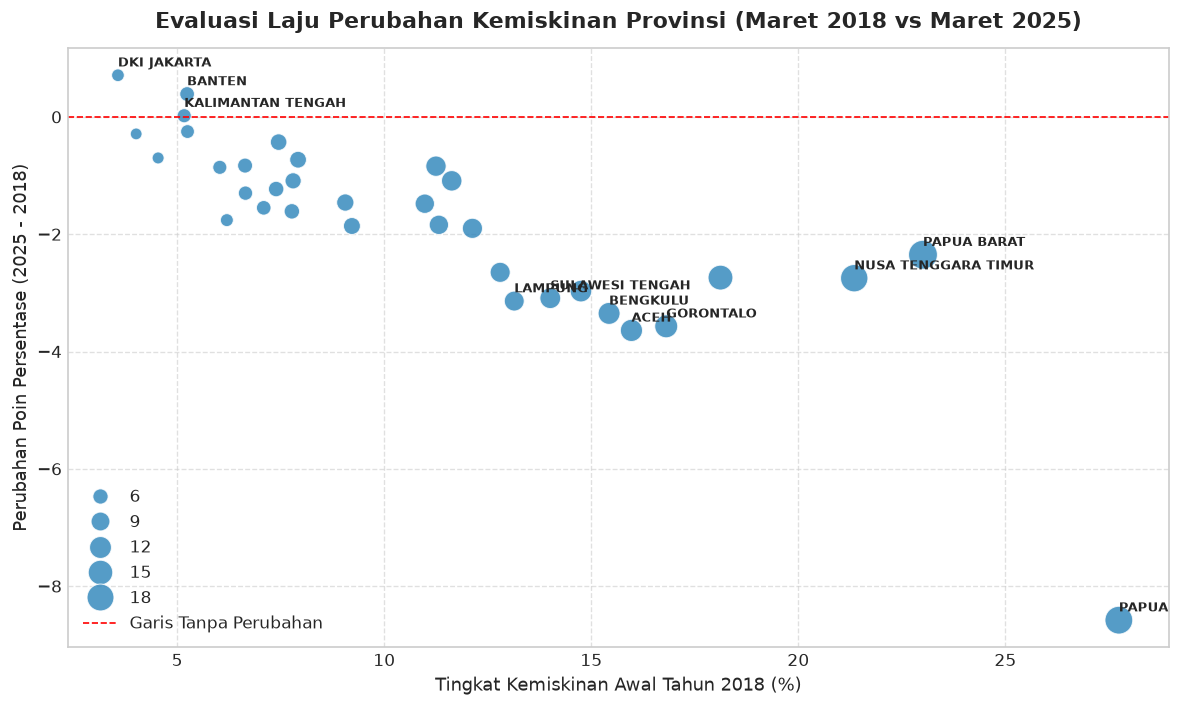

5 Provinsi dengan Penurunan Poin Kemiskinan Terbesar (Kisah Sukses):


,p0_2018,p0_2025,perubahan_poin,persen_penurunan
provinsi,,,,
PAPUA,27.74,19.16,-8.58,-30.93
ACEH,15.97,12.33,-3.64,-22.79
GORONTALO,16.81,13.24,-3.57,-21.24
BENGKULU,15.43,12.08,-3.35,-21.71
LAMPUNG,13.14,10.00,-3.14,-23.90



Provinsi yang Mengalami Peningkatan Kemiskinan / Stagnan:


,p0_2018,p0_2025,perubahan_poin,persen_penurunan
provinsi,,,,
BANTEN,5.24,5.63,0.39,7.44
DKI JAKARTA,3.57,4.28,0.71,19.89
KALIMANTAN TENGAH,5.17,5.19,0.02,0.39


In [9]:
# Menghitung delta perubahan 2018 ke 2025
p18 = df_maret[df_maret['tahun'] == 2018].set_index('provinsi')['total_persen']
p25 = df_maret[df_maret['tahun'] == 2025].set_index('provinsi')['total_persen']

df_delta = pd.DataFrame({'p0_2018': p18, 'p0_2025': p25}).dropna()
df_delta['perubahan_poin'] = df_delta['p0_2025'] - df_delta['p0_2018']
df_delta['persen_penurunan'] = (df_delta['perubahan_poin'] / df_delta['p0_2018']) * 100

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_delta, x='p0_2018', y='perubahan_poin', size='p0_2025', sizes=(50, 300), color='#2b83ba', alpha=0.8)
plt.axhline(0, color='red', linestyle='--', linewidth=1, label='Garis Tanpa Perubahan')
plt.title('Evaluasi Laju Perubahan Kemiskinan Provinsi (Maret 2018 vs Maret 2025)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Tingkat Kemiskinan Awal Tahun 2018 (%)', fontsize=11)
plt.ylabel('Perubahan Poin Persentase (2025 - 2018)', fontsize=11)

# Anotasi daerah menonjol
for prov, row in df_delta.iterrows():
    if row['perubahan_poin'] <= -3.0 or row['p0_2018'] > 20 or row['perubahan_poin'] > 0:
        plt.annotate(prov, (row['p0_2018'], row['perubahan_poin'] + 0.15), fontsize=8, fontweight='semibold')

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

print("5 Provinsi dengan Penurunan Poin Kemiskinan Terbesar (Kisah Sukses):")
display(df_delta.sort_values(by='perubahan_poin').head(5).round(2))

print("\nProvinsi yang Mengalami Peningkatan Kemiskinan / Stagnan:")
display(df_delta[df_delta['perubahan_poin'] >= 0].round(2))


## 🎯 10. Sintesis Storytelling Data & Rekomendasi Kebijakan

### 💡 Temuan Utama (Key Insights)
1. **Lompatan dan Pemulihan Pasca-COVID-19:**
   Kemiskinan nasional sempat mengalami pembalikan arah drastis saat pandemi (melonjak ke 10,19% pada September 2020), namun berhasil pulih bertahap hingga menyentuh level terendah dalam sejarah modern Indonesia di angka **~8,25%–8,47% pada 2025**.
2. **Kesenjangan Struktural Desa-Kota yang Persisten:**
   Rata-rata kemiskinan perdesaan nasional (~11%) tetap hampir dua kali lipat lebih tinggi dari kemiskinan perkotaan (~7%). Provinsi dengan kesenjangan desa-kota terlebar didominasi oleh Papua Barat, Papua, Maluku, dan Nusa Tenggara Timur, di mana kemiskinan perdesaan dapat melampaui 25%–35%.
3. **Polarisasi Geografis (Barat vs Timur):**
   - **Kelompok Sejahtera (<5% miskin):** Bali, DKI Jakarta, Kepulauan Bangka Belitung, Kalimantan Selatan.
   - **Kelompok Kantong Kemiskinan Berat (>20% miskin):** Papua Pegunungan (30,03%), Papua Tengah (28,90%), Papua (19,16%), dan NTT (19,40%).
4. **Keterkaitan Erat dengan Ketahanan Pangan:**
   Karena Garis Kemiskinan Makanan (GKM) mencakup ~74% dari Garis Kemiskinan BPS, lonjakan harga bahan makanan pokok (beras, minyak, telur) memiliki elastisitas yang luar biasa kuat dalam menjerumuskan kelompok rentan miskin (*near-poor*) kembali ke bawah garis kemiskinan.

---

### 📋 Rekomendasi untuk Presentasi & Kebijakan
1. **Fokus Akselerasi Perdesaan:** Alokasi Dana Desa harus diprioritaskan pada produktivitas pertanian rakyat, lumbung pangan lokal, dan jalan usaha tani untuk menutup jurang desa-kota.
2. **Pengendalian Inflasi Pangan Bergejolak (*Volatile Foods*):** Pemerintah daerah wajib menjaga stabilitas harga beras dan sembako melalui operasi pasar terukur guna melindungi daya beli masyarakat miskin.
3. **Perlindungan Sosial Adaptif di Daerah DOB Papua:** Wilayah pemekaran baru di Papua membutuhkan sistem logistik khusus dan bantuan nontunai berbasis kearifan pangan lokal (ubi jalar/sagu) agar program tepat sasaran.
